# EV Charging Optimizer (Delhi): Demand Weights

Builds the shared **demand layer** used by the grid, weighted K-means and MCLP models.
It does not run any siting model.

**Pipeline**
1. Spatial units: 1 km grid (500 m sensitivity) x ward polygons -> *pieces* (each piece in exactly one ward)
2. OSM features per piece: land use, POIs, roads, transit (+ a separate feasibility layer that is not scored)
3. Residential demand **R**: ward `income_total_inr` split across pieces by residential land (dasymetric)
4. Destination demand **D**: percentile-ranked features combined with theta weights
5. Demand score `s = lam*R/sum(R) + (1-lam)*D/sum(D)`, weight `w = N*s/sum(s)`; pieces summed to cells
6. Robustness helpers (Monte Carlo lambda / theta / noise draws) live in `demand_weights_mc.py`
7. Export: `data/delhi_demand_weights.gpkg`, feature table CSV, QA report

> **Update (2026-11-25).** This notebook builds the 1 km layer (R = population, D = destinations). Since the audit, the models use R = EV registrations (cell population x ward VAHAN EV-4W registrations per resident) in place of population, with D and the 60/40 split unchanged. That swap is done downstream (`siting_lib.load_base`, `ev_siting_final.ipynb` section 3), so the layer built here is still the input.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from shapely.geometry import box, Polygon
from scipy.stats import spearmanr

import demand_weights_mc as mc

warnings.filterwarnings("ignore", message=".*organizePolygons.*")
warnings.filterwarnings("ignore", message=".*Non closed ring.*")
pd.set_option("display.width", 160)

## 1. Config and data contract

| Input | Source | Used for |
|---|---|---|
| Ward polygons (250, 2022 delimitation) | `Final Data/delhi_ev_gis_v1.gpkg`, layer `wards` | pieces, ward totals. Stands in for `DELHI Ward Boundaries and Land Use.geojson` (not in the folder); `ward_no` checked against the CSV below |
| Study area | same gpkg, layer `study_area` (250 MCD wards, NDMC + Cantonment excluded, A2/A3) | clipping |
| Ward table | `ward_master_v2.csv` | `population`, `income_total_inr` |
| OSM | `delhi.osm.pbf` (layers points, lines, multipolygons) | land use, POIs, roads, transit, feasibility |

**Ignored on purpose:** `ev_4w_demand` and friends (population x RTO-zone constant), `chargers_*` (later supply variant),
`dist_to_rto_office_km` (registration artefact), `income_pci_inr` (flat).

In [2]:
CFG = dict(
    wards_path="Final Data/delhi_ev_gis_v1.gpkg", wards_layer="wards", study_layer="study_area",
    ward_csv="ward_master_v2.csv",
    osm_path="delhi.osm.pbf",
    crs="EPSG:32643",
    cell_m=1000,                 # 1000 = main run; 500 = sensitivity
    boundary_close_m=300,        # display outline: buffer(+300).buffer(-300), holes filled
    min_piece_m2=1.0,            # drop numerical slivers from ward-boundary overlaps
    dest_unit="cell",            # destination features + percentiles on whole cells ("piece" = per ward piece)
    res_min_cover=0.01,          # ward counts as 'no mapped residential' below this share of its area (0 = literal brief)
    dedup_m=50,                  # merge point / polygon POI duplicates within this distance
    edge_buffer_m=5000,          # distance features look this far outside the study area (edge effect)
    lam=mc.LAMBDA, N=mc.N_TOTAL,
    theta_D=mc.THETA_D, theta_POI=mc.THETA_POI,
    out_dir="data",
)
TAG = "" if CFG["cell_m"] == 1000 else f"_{CFG['cell_m']}m"
OUT = Path(CFG["out_dir"]); OUT.mkdir(exist_ok=True)
CRS = CFG["crs"]
QA = {}                          # everything that goes into the QA report

## 2. Load wards, check numbering, build boundary

In [3]:
wards = gpd.read_file(CFG["wards_path"], layer=CFG["wards_layer"]).to_crs(CRS)[["ward_no", "ward_name", "geometry"]]
wt = pd.read_csv(CFG["ward_csv"])[["ward_no", "ward_name", "population", "area_km2", "income_total_inr"]]
chk = wards.merge(wt, on="ward_no", how="outer", indicator=True, suffixes=("_poly", "_csv"))
QA["ward_match"] = dict(
    n_poly=len(wards), n_csv=len(wt),
    matched=int((chk["_merge"] == "both").sum()),
    name_mismatch=int((chk["ward_name_poly"] != chk["ward_name_csv"]).sum()),
    max_area_diff_km2=float((chk.geometry.area / 1e6 - chk["area_km2"]).abs().max()),
)
assert QA["ward_match"]["matched"] == 250, QA["ward_match"]
print("Ward check:", QA["ward_match"])
wards = wards.merge(wt[["ward_no", "population", "income_total_inr"]], on="ward_no")

study = gpd.read_file(CFG["wards_path"], layer=CFG["study_layer"]).to_crs(CRS)
study_geom = shapely.make_valid(study.union_all())
# display outline per brief (holes filled); NOT used for clipping, so the NDMC hole stays excluded
_b = wards.union_all().buffer(CFG["boundary_close_m"]).buffer(-CFG["boundary_close_m"])
outline = gpd.GeoDataFrame(geometry=[shapely.union_all([Polygon(p.exterior) for p in getattr(_b, "geoms", [_b])])], crs=CRS)
edge_geom = study_geom.buffer(CFG["edge_buffer_m"])
print(f"Study area {study_geom.area/1e6:,.0f} km2 | filled outline {outline.area.iloc[0]/1e6:,.0f} km2")

Ward check: {'n_poly': 250, 'n_csv': 250, 'matched': 250, 'name_mismatch': 0, 'max_area_diff_km2': 0.0}
Study area 1,393 km2 | filled outline 1,486 km2


## 3. Spatial units: grid cells x wards -> pieces

In [4]:
cm = CFG["cell_m"]
minx, miny, maxx, maxy = study_geom.bounds
x0, y0 = np.floor(minx / cm) * cm, np.floor(miny / cm) * cm
xs, ys = np.arange(x0, maxx, cm), np.arange(y0, maxy, cm)
cells = gpd.GeoDataFrame(
    [{"cell_id": f"c{int(x/cm)}_{int(y/cm)}", "ix": int(x / cm), "iy": int(y / cm)} for y in ys for x in xs],
    geometry=[box(x, y, x + cm, y + cm) for y in ys for x in xs], crs=CRS)
cells = cells[cells.intersects(study_geom)].reset_index(drop=True)

pieces = gpd.overlay(cells, wards[["ward_no", "geometry"]], how="intersection", keep_geom_type=True)
pieces["area_m2"] = pieces.area
n_sliver = int((pieces["area_m2"] < CFG["min_piece_m2"]).sum())
pieces = pieces[pieces["area_m2"] >= CFG["min_piece_m2"]].reset_index(drop=True)
pieces["piece_id"] = np.arange(len(pieces))
pieces["area_km2"] = pieces["area_m2"] / 1e6
QA["units"] = dict(cell_m=cm, n_cells=int(pieces["cell_id"].nunique()), n_pieces=len(pieces),
                   slivers_dropped=n_sliver, pieces_area_km2=round(pieces["area_km2"].sum(), 2),
                   wards_area_km2=round(wards.area.sum() / 1e6, 2))
print(QA["units"])

{'cell_m': 1000, 'n_cells': 1570, 'n_pieces': 3259, 'slivers_dropped': 2, 'pieces_area_km2': np.float64(1393.25), 'wards_area_km2': np.float64(1393.25)}


## 4. Read OSM (clip to Delhi)

Points and lines keep most tags in the hstore string `other_tags`; multipolygons have columns for
amenity / shop / office / tourism / landuse. `building=yes` polygons with no other useful tag are skipped.

In [5]:
def tag(s, key):
    """Value of `key` from an OSM hstore string column (NaN if absent)."""
    return s.str.extract(rf'"{key}"=>"([^"]*)"', expand=False)


t0 = time.time()
P = CFG["osm_path"]
pts = gpd.read_file(P, layer="points", where="other_tags IS NOT NULL").to_crs(CRS)
pts = pts[pts.within(edge_geom)].reset_index(drop=True)
for k in ["amenity", "shop", "tourism", "office", "building", "power", "railway", "station",
          "subway", "public_transport", "network"]:
    pts[k] = tag(pts["other_tags"], k)

mp = gpd.read_file(P, layer="multipolygons",
                   where="building IS NULL OR building<>'yes' OR amenity IS NOT NULL OR shop IS NOT NULL "
                         "OR office IS NOT NULL OR tourism IS NOT NULL").to_crs(CRS)
mp = mp[mp.intersects(edge_geom)].reset_index(drop=True)
for k in ["power", "railway", "station", "subway", "public_transport", "network"]:
    mp[k] = tag(mp["other_tags"], k)

ln = gpd.read_file(P, layer="lines", where="highway IS NOT NULL", columns=["osm_id", "highway"]).to_crs(CRS)
ln = ln[ln.intersects(edge_geom)].reset_index(drop=True)
print(f"OSM read in {time.time()-t0:.0f}s | points {len(pts):,} | polygons {len(mp):,} | road lines {len(ln):,} "
      f"(within study area + {CFG['edge_buffer_m']/1000:.0f} km)")

OSM read in 4s | points 79,271 | polygons 41,108 | road lines 202,860 (within study area + 5 km)


## 5. Land-use shares per piece (overlay)

In [6]:
LU = {"residential": ["residential"], "commercial": ["commercial", "retail"], "industrial": ["industrial"]}
lu = mp[mp["landuse"].isin(sum(LU.values(), []))][["landuse", "geometry"]].copy()
lu["cls"] = lu["landuse"].map({v: k for k, vs in LU.items() for v in vs})
lu["geometry"] = shapely.make_valid(lu.geometry.values)
lu = lu.explode(index_parts=False)
lu = lu[lu.geom_type.isin(["Polygon", "MultiPolygon"])]
lu = lu.dissolve("cls").reset_index()[["cls", "geometry"]].explode(index_parts=False)   # overlaps within a class removed
lu = lu.clip(study_geom)

ov = gpd.overlay(pieces[["piece_id", "geometry"]], lu, how="intersection", keep_geom_type=True)
ov["a"] = ov.area
lu_area = ov.pivot_table(index="piece_id", columns="cls", values="a", aggfunc="sum").reindex(pieces["piece_id"]).fillna(0)
for c in LU:
    pieces[f"lu_{c}_m2"] = lu_area.get(c, 0).to_numpy()
    pieces[f"lu_{c}_share"] = (pieces[f"lu_{c}_m2"] / pieces["area_m2"]).clip(0, 1)
pieces["lu_ci_share"] = (pieces["lu_commercial_share"] + pieces["lu_industrial_share"]).clip(0, 1)
QA["landuse_km2"] = {c: round(pieces[f"lu_{c}_m2"].sum() / 1e6, 2) for c in LU}
print("Mapped land use in study area (km2):", QA["landuse_km2"])

Mapped land use in study area (km2): {'residential': np.float64(281.0), 'commercial': np.float64(14.69), 'industrial': np.float64(55.07)}


## 6. POIs (destination features) and feasibility layer

Polygons -> centroids. A point is dropped as a duplicate if it lies inside a polygon of the same
category or within `dedup_m` of that polygon's centroid. Only features whose point falls inside the
study area are counted.

In [7]:
def dedup(pt, pg, d=CFG["dedup_m"]):
    pt = pt[["geometry"]].reset_index(drop=True)
    pg = pg[["geometry"]].reset_index(drop=True)
    cen = gpd.GeoDataFrame(geometry=pg.geometry.centroid, crs=CRS)
    drop = set()
    if len(pg) and len(pt):
        drop |= set(gpd.sjoin(pt, pg, predicate="within").index)
        drop |= set(gpd.sjoin_nearest(pt, cen, max_distance=d).index)
    out = pd.concat([pt.drop(index=list(drop)).assign(src="point"), cen.assign(src="polygon")], ignore_index=True)
    return gpd.GeoDataFrame(out, geometry="geometry", crs=CRS), len(drop)


RULES = {   # category: (points mask, polygons mask)
    "office":   (pts["office"].notna() | (pts["building"] == "office"), mp["office"].notna() | (mp["building"] == "office")),
    "mall":     (pts["shop"] == "mall", mp["shop"] == "mall"),
    "hospital": (pts["amenity"] == "hospital", mp["amenity"] == "hospital"),
    "hotel":    (pts["tourism"] == "hotel", mp["tourism"] == "hotel"),
    "parking":  (pts["amenity"] == "parking", mp["amenity"] == "parking"),
    # feasibility / supply (NOT scored)
    "fuel":       (pts["amenity"] == "fuel", mp["amenity"] == "fuel"),
    "substation": (pts["power"] == "substation", mp["power"] == "substation"),
    "charging":   (pts["amenity"] == "charging_station", mp["amenity"] == "charging_station"),
}
POI_CATS = list(CFG["theta_POI"])
poi, poi_qa = {}, []
for cat, (mpt, mpg) in RULES.items():
    g, n_drop = dedup(pts[mpt], mp[mpg])
    g = g[g.within(study_geom)].reset_index(drop=True)
    poi[cat] = g
    poi_qa.append(dict(category=cat, scored=cat in POI_CATS,
                       points_in_area=int(pts[mpt].within(study_geom).sum()),
                       polygons_in_area=int(mp[mpg].centroid.within(study_geom).sum()),
                       duplicates_dropped=n_drop, final=len(g)))
poi_qa = pd.DataFrame(poi_qa)
poi_qa.loc[poi_qa["category"] == "substation", "note"] = "UNRELIABLE: OSM substations heavily undercounted"
poi_qa.loc[poi_qa["category"] == "parking", "note"] = "undercounted in OSM; also a feasible site"
poi_qa

,category,scored,points_in_area,polygons_in_area,duplicates_dropped,final,note
0,office,True,949,296,142,1153,NaN
1,mall,True,14,49,5,62,NaN
2,hospital,True,490,135,28,605,NaN
3,hotel,True,326,62,13,375,NaN
4,parking,True,67,431,11,488,undercounted in OSM; also a feasible site
5,fuel,False,222,112,15,323,NaN
6,substation,False,55,7,0,62,UNRELIABLE: OSM substations heavily undercounted
7,charging,False,120,3,1,122,NaN


In [8]:
pc = pieces[["piece_id", "geometry"]]
for cat in POI_CATS:
    j = gpd.sjoin(poi[cat], pc, predicate="within")
    pieces[f"n_{cat}"] = pieces["piece_id"].map(j.groupby("piece_id").size()).fillna(0).astype(int)
    pieces[f"dens_{cat}"] = pieces[f"n_{cat}"] / pieces["area_km2"]
pieces[[f"n_{c}" for c in POI_CATS]].sum()

n_office      1153
n_mall          62
n_hospital     605
n_hotel        375
n_parking      488
dtype: int64

## 7. Roads and transit

* **Arterials** = highway in {motorway, trunk, primary, secondary} (links excluded). Length density in km/km2.
* **Intersections** = nodes where the drivable network (motorway ... residential, living_street,
  unclassified + links; `service` excluded so parking aisles do not count) has degree >= 3.
  OSM ways are not split at junctions, so degree = 2 per way the node is interior to + 1 per way it ends.
* **Distances** (arterial, transit) are straight-line from the piece centroid and may reach features up to
  `edge_buffer_m` outside the study area, so wards next to NDMC are not penalised for the excluded hole.

In [9]:
ART = ["motorway", "trunk", "primary", "secondary"]
DRIVE = ART + ["tertiary", "unclassified", "residential", "living_street",
               "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link"]

art = ln[ln["highway"].isin(ART)].reset_index(drop=True)
ai = gpd.overlay(art[["geometry"]], pc, how="intersection", keep_geom_type=True)
ai["km"] = ai.length / 1000
pieces["art_km"] = pieces["piece_id"].map(ai.groupby("piece_id")["km"].sum()).fillna(0)
pieces["art_density"] = pieces["art_km"] / pieces["area_km2"]

drv = ln[ln["highway"].isin(DRIVE)].geometry.values
xy, idx = shapely.get_coordinates(drv, return_index=True)
is_end = np.r_[True, idx[1:] != idx[:-1]] | np.r_[idx[1:] != idx[:-1], True]
nodes = pd.DataFrame({"x": np.round(xy[:, 0], 2), "y": np.round(xy[:, 1], 2), "deg": np.where(is_end, 1, 2)})
nodes = nodes.groupby(["x", "y"], as_index=False)["deg"].sum()
inter = nodes[nodes["deg"] >= 3]
inter = gpd.GeoDataFrame(geometry=gpd.points_from_xy(inter["x"], inter["y"]), crs=CRS)
ji = gpd.sjoin(inter, pc, predicate="within")
pieces["n_intersections"] = pieces["piece_id"].map(ji.groupby("piece_id").size()).fillna(0).astype(int)
pieces["int_density"] = pieces["n_intersections"] / pieces["area_km2"]
QA["roads"] = dict(arterial_km_in_area=round(pieces["art_km"].sum(), 1),
                   intersections_in_area=int(pieces["n_intersections"].sum()))

cent = gpd.GeoDataFrame(pieces[["piece_id"]], geometry=pieces.geometry.centroid, crs=CRS)
d = gpd.sjoin_nearest(cent, art[["geometry"]], distance_col="d").groupby("piece_id")["d"].min()
pieces["dist_arterial_m"] = pieces["piece_id"].map(d)

is_metro_pt = pts["railway"].eq("station") | pts["public_transport"].eq("station")
is_metro_pt &= pts["station"].eq("subway") | pts["subway"].eq("yes") | pts["network"].str.contains("Metro", na=False)
is_metro_pg = (mp["railway"].eq("station") | mp["public_transport"].eq("station")) & \
              (mp["station"].eq("subway") | mp["subway"].eq("yes") | mp["network"].str.contains("Metro", na=False))
transit = pd.concat([
    pts.loc[is_metro_pt, ["geometry"]].assign(kind="metro"),
    gpd.GeoDataFrame(geometry=mp.loc[is_metro_pg].centroid, crs=CRS).assign(kind="metro"),
    pts.loc[pts["amenity"] == "bus_station", ["geometry"]].assign(kind="bus_terminal"),
    gpd.GeoDataFrame(geometry=mp.loc[mp["amenity"] == "bus_station"].centroid, crs=CRS).assign(kind="bus_terminal"),
], ignore_index=True)
transit = gpd.GeoDataFrame(transit, geometry="geometry", crs=CRS)
d = gpd.sjoin_nearest(cent, transit[["geometry"]], distance_col="d").groupby("piece_id")["d"].min()
pieces["dist_transit_m"] = pieces["piece_id"].map(d)
QA["transit"] = transit.assign(in_area=transit.within(study_geom)).groupby("kind")["in_area"].agg(["size", "sum"]) \
    .rename(columns={"size": "within_area_plus_buffer", "sum": "within_study_area"}).to_dict("index")
print(QA["roads"], QA["transit"])

{'arterial_km_in_area': np.float64(1870.9), 'intersections_in_area': 166593} {'bus_terminal': {'within_area_plus_buffer': 65, 'within_study_area': 59}, 'metro': {'within_area_plus_buffer': 244, 'within_study_area': 194}}


## 8. Residential demand R (dasymetric)

Each ward's `income_total_inr` is split across its pieces in proportion to mapped residential land.
Wards with no mapped residential land fall back to piece-area share. "No mapped residential land" is taken
as residential cover < `res_min_cover` (default 1% of ward area): a few wards have only tens of m2 tagged
residential (edge slivers of a neighbour's polygon), which would otherwise put a whole ward's population into
that sliver. Set `res_min_cover=0` for the literal rule. `income_pci_inr` is flat, so
`income_total_inr` = population x 493,024 and **R is effectively population** until real ward income exists.
`pop_alloc` (population split the same way) is kept for evaluation only; it is not added to R.

In [10]:
g = pieces.groupby("ward_no")
ward_res = g["lu_residential_m2"].transform("sum")
ward_area = g["area_m2"].transform("sum")
pieces["r_fallback"] = (ward_res <= 0) | (ward_res < CFG["res_min_cover"] * ward_area)
pieces["r_share"] = np.where(pieces["r_fallback"], pieces["area_m2"] / ward_area,
                             pieces["lu_residential_m2"] / ward_res.where(~pieces["r_fallback"], 1))
pieces = pieces.merge(wards[["ward_no", "income_total_inr", "population"]], on="ward_no", how="left")
pieces["R"] = pieces["income_total_inr"] * pieces["r_share"]
pieces["pop_alloc"] = pieces["population"] * pieces["r_share"]

mass = pieces.groupby("ward_no").agg(R=("R", "sum"), tot=("income_total_inr", "first"),
                                     res_km2=("lu_residential_m2", lambda s: s.sum() / 1e6),
                                     area_km2=("area_km2", "sum"), fallback=("r_fallback", "first"))
mass["rel_err"] = (mass["R"] / mass["tot"] - 1).abs()
mass["res_cover"] = mass["res_km2"] / mass["area_km2"]
QA["mass"] = dict(max_rel_err=float(mass["rel_err"].max()),
                  total_R=float(pieces["R"].sum()), total_ward=float(wards["income_total_inr"].sum()),
                  n_fallback=int(mass["fallback"].sum()),
                  fallback_wards=mass.index[mass["fallback"]].tolist(),
                  n_no_res=int((mass["res_km2"] <= 0).sum()),
                  n_res_cover_lt_10pct=int(((mass["res_cover"] < 0.10) & ~mass["fallback"]).sum()),
                  median_res_cover=float(mass["res_cover"].median()))
assert QA["mass"]["max_rel_err"] < 1e-9
print({k: v for k, v in QA["mass"].items() if k != "fallback_wards"})

{'max_rel_err': 3.3306690738754696e-16, 'total_R': 8095349065888.0, 'total_ward': 8095349065888.0, 'n_fallback': 33, 'n_no_res': 26, 'n_res_cover_lt_10pct': 41, 'median_res_cover': 0.31644718919005516}


## 9. Destination demand D

**Unit.** With `dest_unit="cell"` (default) destination features are measured on **whole grid cells**
(counts summed over the cell's pieces, distances from the cell point) and ranked across cells. Measuring them
per piece made ward-boundary slivers look extreme (1 office in 0.01 km2 = 100 offices/km2), which pushed
ordinary cells down the ranking. Each piece then takes its cell's `D_index`; R stays per piece because it
needs the ward.

Every feature -> 0-1 percentile score across units:
* **Count / share features** (POI densities, C+I land share, arterial density, intersection density) are
  zero-inflated (most units have no office, mall, C+I land, ...). A plain rank would push the first
  nonzero value near the top (0.25% C+I land scored 0.79). So **zero stays 0 and nonzero values are ranked
  among nonzero units only**, giving (0, 1]: the score says *how much*, not just *whether any*.
* **Distance features** (arterial, transit) have no zeros: plain percentile rank, inverted so closer = higher.

```
POI index  = 0.25 office + 0.25 mall + 0.20 hospital + 0.15 hotel + 0.15 parking
Road index = (arterial density + intersection density + arterial proximity) / 3
D_index    = 0.35 POI + 0.30 C+I land share + 0.20 road + 0.15 transit proximity
```
The theta values are the **team's reasoned starting values, not taken from literature**.

**D as a mass.** `D_index` is an intensity (0-1) while R is a mass (rupees / people). Pieces differ a lot
in size (boundary slivers vs full cells), so `D = D_index x area_km2` before the shares are formed;
otherwise splitting a cell into more pieces would multiply its destination demand.

In [11]:
def pct(x):
    """Plain percentile rank in [0, 1] (used for distances)."""
    x = pd.Series(x)
    return (x.rank(method="min") - 1) / (len(x) - 1)


def pct_nz(x):
    """Zero-inflated features: 0 stays 0, nonzero ranked among nonzero only -> (0, 1]."""
    x = pd.Series(x)
    out = pd.Series(0.0, index=x.index)
    nz = x > 0
    out[nz] = x[nz].rank(method="average") / nz.sum()
    return out


def cell_points(gdf):
    """Dissolve pieces to cells; point = centroid, or representative point if the centroid falls outside."""
    cg = gdf.dissolve("cell_id")[["geometry"]]
    p = cg.centroid
    out = ~p.within(cg.geometry)
    p[out] = cg.geometry[out].representative_point()
    return cg, p


if CFG["dest_unit"] == "cell":
    cell_poly, cell_pt = cell_points(pieces)
    U = pieces.groupby("cell_id")[["area_m2", "area_km2", "art_km", "n_intersections", "lu_commercial_m2",
                                   "lu_industrial_m2"] + [f"n_{c}" for c in POI_CATS]].sum()
    for c in POI_CATS:
        U[f"dens_{c}"] = U[f"n_{c}"] / U["area_km2"]
    U["lu_ci_share"] = ((U["lu_commercial_m2"] + U["lu_industrial_m2"]) / U["area_m2"]).clip(0, 1)
    U["art_density"] = U["art_km"] / U["area_km2"]
    U["int_density"] = U["n_intersections"] / U["area_km2"]
    cp_ = gpd.GeoDataFrame({"cell_id": U.index}, geometry=cell_pt.reindex(U.index).values, crs=CRS)
    for col, tgt in [("dist_arterial_m", art), ("dist_transit_m", transit)]:
        U[col] = gpd.sjoin_nearest(cp_, tgt[["geometry"]], distance_col="d").groupby("cell_id")["d"].min()
    QA["edge_cells_small"] = int((U["area_m2"] < 0.25 * CFG["cell_m"] ** 2).sum())   # < 1/4 of a full cell
else:
    U = pieces.set_index("piece_id")

QA["zero_share"] = {c: round(float((U[v] == 0).mean()), 3) for c, v in
                    [*[(c, f"dens_{c}") for c in POI_CATS], ("ci_land", "lu_ci_share"),
                     ("art_density", "art_density"), ("int_density", "int_density")]}

for c in POI_CATS:
    U[f"p_{c}"] = pct_nz(U[f"dens_{c}"])
U["p_ci_land"] = pct_nz(U["lu_ci_share"])
U["p_art_density"] = pct_nz(U["art_density"])
U["p_int_density"] = pct_nz(U["int_density"])
U["p_art_prox"] = pct(-U["dist_arterial_m"])
U["p_transit_prox"] = pct(-U["dist_transit_m"])
key = "cell_id" if CFG["dest_unit"] == "cell" else "piece_id"
_PC = [f"p_{c}" for c in POI_CATS] + ["p_ci_land", "p_art_density", "p_int_density", "p_art_prox", "p_transit_prox"]
for c in _PC:
    pieces[c] = pieces[key].map(U[c]).to_numpy()      # each piece takes its unit's score

COMP = ["poi_idx", "land_idx", "road_idx", "transit_idx"]
pieces["poi_idx"] = sum(CFG["theta_POI"][c] * pieces[f"p_{c}"] for c in POI_CATS)
pieces["land_idx"] = pieces["p_ci_land"]
pieces["road_idx"] = (pieces["p_art_density"] + pieces["p_int_density"] + pieces["p_art_prox"]) / 3
pieces["transit_idx"] = pieces["p_transit_prox"]
th = CFG["theta_D"]
pieces["D_index"] = (th["poi"] * pieces["poi_idx"] + th["land"] * pieces["land_idx"]
                     + th["road"] * pieces["road_idx"] + th["transit"] * pieces["transit_idx"])
pieces["D"] = pieces["D_index"] * pieces["area_km2"]

# component masses: let weights be rebuilt for any lambda / theta (see demand_weights_mc.py)
PCOLS = [f"p_{c}" for c in POI_CATS] + ["p_ci_land", "p_art_density", "p_int_density", "p_art_prox", "p_transit_prox"]
for c in PCOLS:
    pieces["Dm_" + c[2:]] = pieces[c] * pieces["area_km2"]

## 10. Demand score and weights

In [12]:
lam, N = CFG["lam"], CFG["N"]
pieces["s"] = lam * pieces["R"] / pieces["R"].sum() + (1 - lam) * pieces["D"] / pieces["D"].sum()
pieces["weight"] = N * pieces["s"] / pieces["s"].sum()
assert np.allclose(mc.recompute_weights(pieces), pieces["weight"])
pieces[["R", "D", "s", "weight"]].describe().T

,count,mean,std,min,25%,50%,75%,max
R,3259.0,2.483998e+09,4.625788e+09,0.000000e+00,0.000000,2.708492e+08,2.810613e+09,3.888332e+10
D,3259.0,1.007483e-01,1.111569e-01,1.072259e-07,0.016862,6.458054e-02,1.446933e-01,7.017043e-01
s,3259.0,3.068426e-04,4.149330e-04,2.316417e-10,0.000035,1.417156e-04,4.143897e-04,3.360180e-03
weight,3259.0,3.068426e-01,4.149330e-01,2.316417e-07,0.035291,1.417156e-01,4.143897e-01,3.360180e+00


### Aggregate pieces to cells
Sums for masses (R, D, s, weight, counts, Dm_*). Densities are recomputed from cell totals; land shares and
percentiles are area-weighted means of the cell's pieces (with `dest_unit="cell"` every piece already carries
its cell's percentiles, so the mean is the cell value; distances are the cell-point distances). `ward_no` = ward holding the
largest share of the cell. Each cell is a Point at its centroid (representative point if the clipped
cell's centroid falls outside it).

In [13]:
SUM = ["area_m2", "area_km2", "R", "pop_alloc", "D", "s", "weight", "art_km", "n_intersections",
       "lu_residential_m2", "lu_commercial_m2", "lu_industrial_m2"] + [f"n_{c}" for c in POI_CATS] + \
      [c for c in pieces.columns if c.startswith("Dm_")]
AWM = ["dist_arterial_m", "dist_transit_m", "D_index"] + COMP + PCOLS

pa = pieces.copy()
for c in AWM:
    pa[c] = pa[c] * pa["area_m2"]
agg = pa.groupby("cell_id")[SUM + AWM].sum()
agg[AWM] = agg[AWM].div(agg["area_m2"], axis=0)
for c in POI_CATS:
    agg[f"dens_{c}"] = agg[f"n_{c}"] / agg["area_km2"]
agg["art_density"] = agg["art_km"] / agg["area_km2"]
agg["int_density"] = agg["n_intersections"] / agg["area_km2"]
for c in ["residential", "commercial", "industrial"]:
    agg[f"lu_{c}_share"] = agg[f"lu_{c}_m2"] / agg["area_m2"]
agg["lu_ci_share"] = agg["lu_commercial_share"] + agg["lu_industrial_share"]
if CFG["dest_unit"] == "cell":                    # report the distances that were actually scored
    agg[["dist_arterial_m", "dist_transit_m"]] = U[["dist_arterial_m", "dist_transit_m"]]
main = pieces.sort_values("area_m2").groupby("cell_id").tail(1).set_index("cell_id")
agg["ward_no"] = main["ward_no"]
agg["n_wards"] = pieces.groupby("cell_id")["ward_no"].nunique()
agg["r_fallback_any"] = pieces.groupby("cell_id")["r_fallback"].any()

cell_poly = pieces.dissolve("cell_id")[["geometry"]]
pt = cell_poly.centroid
inside = pt.within(cell_poly.geometry)
pt[~inside] = cell_poly.geometry[~inside].representative_point()
COLS = (["cell_id", "ward_no", "n_wards", "weight", "R", "D", "s", "pop_alloc", "D_index", "area_km2"]
        + COMP
        + [f"n_{c}" for c in POI_CATS] + [f"dens_{c}" for c in POI_CATS]
        + ["lu_residential_share", "lu_commercial_share", "lu_industrial_share", "lu_ci_share",
           "art_km", "art_density", "n_intersections", "int_density", "dist_arterial_m", "dist_transit_m"]
        + PCOLS + [c for c in agg.columns if c.startswith("Dm_")] + ["r_fallback_any"])
demand_weights = gpd.GeoDataFrame(agg.join(pt.rename("geometry")).reset_index(), geometry="geometry", crs=CRS)[COLS + ["geometry"]]
assert np.allclose(mc.recompute_weights(demand_weights), demand_weights["weight"])
assert abs(demand_weights["weight"].sum() - N) < 1e-6
print(f"{len(demand_weights)} demand points | weight sum {demand_weights['weight'].sum():.1f}")
demand_weights.head()

1570 demand points | weight sum 1000.0


,cell_id,ward_no,n_wards,weight,R,D,s,pop_alloc,D_index,area_km2,...,Dm_hospital,Dm_hotel,Dm_parking,Dm_ci_land,Dm_art_density,Dm_int_density,Dm_art_prox,Dm_transit_prox,r_fallback_any,geometry
0,c679_3161,126,1,0.000490,0.0,0.000403,4.904745e-07,0.0,0.042925,0.009379,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.003389,0.001178,False,POINT (679971.981 3161908.088)
1,c679_3162,126,1,0.005682,0.0,0.004664,5.682323e-06,0.0,0.034651,0.134610,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.027111,0.019046,False,POINT (679932.403 3162487.473)
2,c679_3163,126,1,0.000699,0.0,0.000574,6.989916e-07,0.0,0.037147,0.015446,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.003003,0.002491,False,POINT (679942.934 3163066.416)
3,c680_3159,126,1,0.011625,0.0,0.009542,1.162451e-05,0.0,0.032356,0.294904,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.096610,0.020675,False,POINT (680744.059 3159733.584)
4,c680_3160,126,1,0.093094,0.0,0.076415,9.309353e-05,0.0,0.096631,0.790798,...,0.0,0.0,0.0,0.0,0.395882,0.0,0.583648,0.074090,False,POINT (680603.367 3160511.58)


## 11. Sensitivity of the weights themselves

Alternatives to the base theta and lambda, compared on the cell weights by Spearman rank correlation with the
base and by overlap of the top-10% cells. Entropy and PCA weights are derived from the four D components
across pieces.

In [14]:
X = (demand_weights if CFG["dest_unit"] == "cell" else pieces)[COMP].to_numpy()
P_ = X / X.sum(0)
e = -(P_ * np.log(np.where(P_ > 0, P_, 1))).sum(0) / np.log(len(X))
th_entropy = (1 - e) / (1 - e).sum()
Z = (X - X.mean(0)) / X.std(0)
evals, evecs = np.linalg.eigh(np.cov(Z.T))
pc1 = np.abs(evecs[:, -1]); th_pca = pc1 / pc1.sum()
pca_var = evals[-1] / evals.sum()

keys = ["poi", "land", "road", "transit"]
variants = {
    "base (team theta, lam=0.6)": (0.6, CFG["theta_D"], CFG["theta_POI"]),
    "equal theta within D": (0.6, dict.fromkeys(keys, 0.25), dict.fromkeys(POI_CATS, 0.2)),
    "entropy theta": (0.6, dict(zip(keys, th_entropy)), CFG["theta_POI"]),
    f"PCA PC1 theta ({pca_var:.0%} var)": (0.6, dict(zip(keys, th_pca)), CFG["theta_POI"]),
}
for l in [0.3, 0.45, 0.8, 1.0, 0.0]:
    variants[f"lam={l}"] = (l, CFG["theta_D"], CFG["theta_POI"])

base_w = demand_weights["weight"].to_numpy()
top = lambda w: set(np.argsort(-w)[: int(0.1 * len(w))])
rows = []
for name, (l, td, tp) in variants.items():
    w_ = mc.recompute_weights(demand_weights, l, td, tp)
    rows.append(dict(variant=name, lam=l, **{f"th_{k}": round(td[k], 3) for k in keys},
                     spearman_vs_base=round(spearmanr(base_w, w_)[0], 3),
                     top10pct_overlap=round(len(top(base_w) & top(w_)) / len(top(base_w)), 3)))
sens = pd.DataFrame(rows)
rho_RD = spearmanr(demand_weights["R"], demand_weights["D"])[0]
print(f"Spearman(R, D) across cells = {rho_RD:.2f}")
sens

Spearman(R, D) across cells = 0.61


,variant,lam,th_poi,th_land,th_road,th_transit,spearman_vs_base,top10pct_overlap
0,"base (team theta, lam=0.6)",0.60,0.350,0.300,0.200,0.150,1.000,1.000
1,equal theta within D,0.60,0.250,0.250,0.250,0.250,0.998,0.962
2,entropy theta,0.60,0.438,0.426,0.074,0.062,0.993,0.911
3,PCA PC1 theta (58% var),0.60,0.252,0.191,0.276,0.282,0.996,0.936
4,lam=0.3,0.30,0.350,0.300,0.200,0.150,0.978,0.726
5,lam=0.45,0.45,0.350,0.300,0.200,0.150,0.995,0.904
6,lam=0.8,0.80,0.350,0.300,0.200,0.150,0.991,0.917
7,lam=1.0,1.00,0.350,0.300,0.200,0.150,0.884,0.898
8,lam=0.0,0.00,0.350,0.300,0.200,0.150,0.867,0.242


## 12. Maps

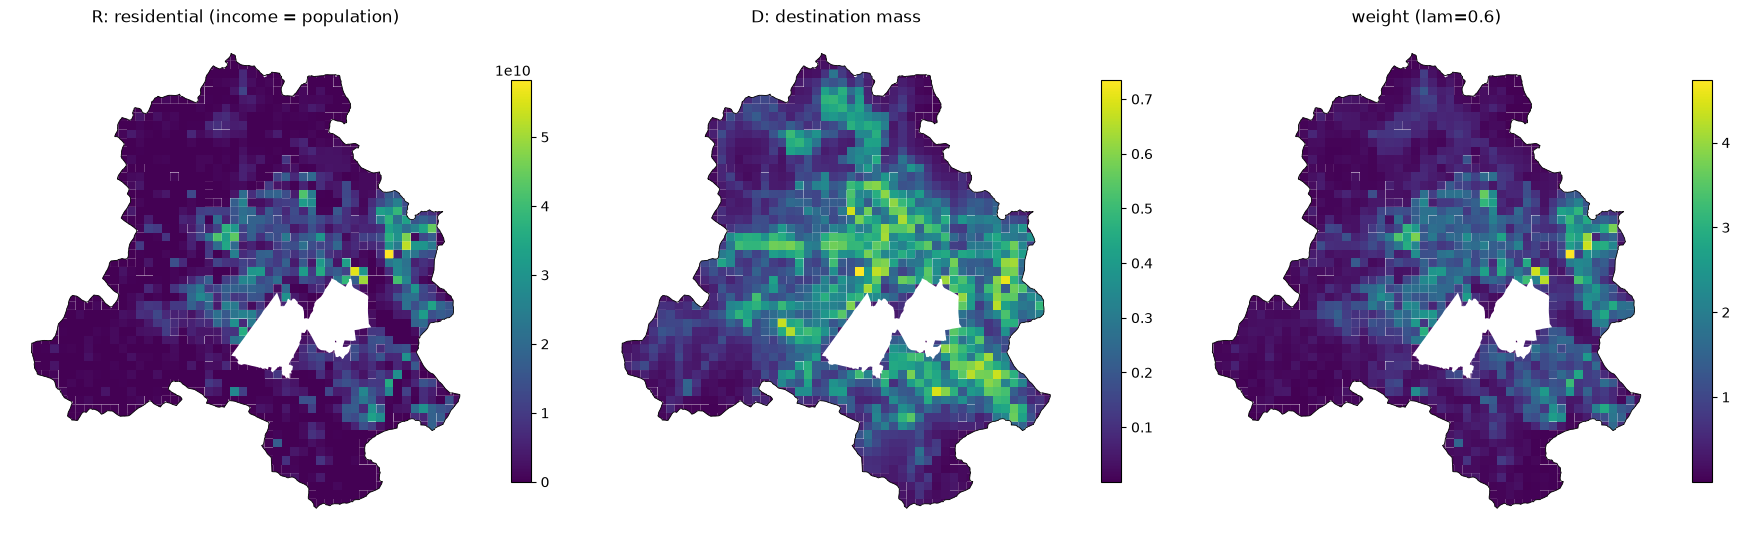

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
cp = cell_poly.reset_index().merge(demand_weights[["cell_id", "R", "D", "weight"]], on="cell_id")
for ax, col, ttl in zip(axes, ["R", "D", "weight"],
                        ["R: residential (income = population)", "D: destination mass", f"weight (lam={lam})"]):
    cp.plot(column=col, ax=ax, cmap="viridis", scheme=None, legend=True, legend_kwds={"shrink": 0.6})
    outline.boundary.plot(ax=ax, color="k", lw=0.6)
    ax.set_title(ttl); ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / f"delhi_demand_weights_map{TAG}.png", dpi=130)
plt.show()

## 13. Export

In [16]:
gpkg = OUT / f"delhi_demand_weights{TAG}.gpkg"
if gpkg.exists():
    gpkg.unlink()                                  # this script owns this file; rebuilt each run
demand_weights.to_file(gpkg, layer="demand_weights", driver="GPKG")
gpd.GeoDataFrame(pieces.drop(columns=["geometry"]), geometry=pieces.geometry.centroid, crs=CRS) \
    .to_file(gpkg, layer="demand_pieces", driver="GPKG")
cp.to_file(gpkg, layer="cells_polygons", driver="GPKG")
for cat in ["parking", "fuel", "substation", "charging"]:
    poi[cat].to_file(gpkg, layer=f"feasible_{cat}" if cat != "charging" else "existing_charging_osm", driver="GPKG")
transit.to_file(gpkg, layer="transit_nodes", driver="GPKG")
outline.to_file(gpkg, layer="delhi_outline_filled", driver="GPKG")
demand_weights.drop(columns="geometry").assign(x=demand_weights.geometry.x, y=demand_weights.geometry.y) \
    .to_csv(OUT / f"delhi_demand_weights_features{TAG}.csv", index=False)
sens.to_csv(OUT / f"delhi_demand_weights_sensitivity{TAG}.csv", index=False)
print("Saved", gpkg)

Saved data/delhi_demand_weights.gpkg


## 14. QA report

In [17]:
dw = demand_weights
zero_w = int((dw["weight"] <= 0).sum())
qa_md = f"""# Demand weights QA report ({cm} m cells)

Generated by `demand_weights.ipynb`. Layer: `{gpkg}` (layer `demand_weights`), CRS {CRS}.

## Inputs and ward check
- Ward polygons: `{CFG['wards_path']}` layer `{CFG['wards_layer']}` (the GeoJSON named in the brief is not in the folder).
- Polygons {QA['ward_match']['n_poly']}, CSV rows {QA['ward_match']['n_csv']}, matched on `ward_no` {QA['ward_match']['matched']},
  name mismatches {QA['ward_match']['name_mismatch']}, max area difference {QA['ward_match']['max_area_diff_km2']:.2e} km2.
- Clipping uses `study_area` (250 MCD wards; NDMC + Cantonment excluded, A2/A3). The hole-filled outline
  (buffer +/-{CFG['boundary_close_m']} m) is saved for display only.

## Spatial units
- Cells: {QA['units']['n_cells']} | pieces: {QA['units']['n_pieces']} | slivers < {CFG['min_piece_m2']} m2 dropped: {QA['units']['slivers_dropped']}
- Area in pieces {QA['units']['pieces_area_km2']} km2 vs wards {QA['units']['wards_area_km2']} km2.

## R: mass preservation
- Max relative error per ward: {QA['mass']['max_rel_err']:.2e} (sum of pieces = ward total).
- Total R {QA['mass']['total_R']:.4e} vs ward total {QA['mass']['total_ward']:.4e}.
- Wards using the area fallback: **{QA['mass']['n_fallback']}** ({QA['mass']['n_no_res']} with no residential land at all, the rest with
  cover < {CFG['res_min_cover']:.0%} of ward area): {QA['mass']['fallback_wards']}
- Wards with residential cover < 10% of ward area (still dasymetric, so population is concentrated in a small
  mapped area): {QA['mass']['n_res_cover_lt_10pct']}. Median residential cover: {QA['mass']['median_res_cover']:.0%}.
- Mapped land use inside the study area (km2): {QA['landuse_km2']}

## POI counts after clipping and de-duplication
{poi_qa.to_markdown(index=False)}

Transit nodes (metro stations + bus terminals): {QA['transit']}
Roads: {QA['roads']}

## Weights
- Demand points: {len(dw)}; weight sum = {dw['weight'].sum():.1f} (N = {N:g}); lambda = {lam}.
- Cells with zero weight: **{zero_w}**; zero R: {int((dw['R'] <= 0).sum())}; zero D: {int((dw['D'] <= 0).sum())}.
- Cells with implied population density > 130k/km2 (the densest ward in the CSV): {int((dw['pop_alloc']/dw['area_km2'] > 130_000).sum())}; max {(dw['pop_alloc']/dw['area_km2']).max():,.0f}/km2.
- Share of weight in top 10% of cells: {np.sort(dw['weight'])[::-1][: len(dw)//10].sum() / N:.0%}.
- Spearman(R, D) across cells: {rho_RD:.2f}.
- Theta (team's reasoned starting values, NOT from literature): D {CFG['theta_D']}, POI {CFG['theta_POI']}.

## Sensitivity of the weights
{sens.to_markdown(index=False)}

## Method notes (new assumptions to log)
- D is used as a mass: `D = D_index x piece area (km2)`, because R is a mass and pieces differ in size.
- Dasymetric fallback threshold: a ward with residential cover < {CFG['res_min_cover']:.0%} of its area is treated as unmapped (area share).
- Percentile scores: count/share features (POIs, C+I land, arterial and intersection density) use a
  nonzero-only rank (0 stays 0; nonzero ranked among nonzero units, in (0, 1]) because they are zero-inflated
  (share of units at 0: {QA['zero_share']}). A plain rank scored 0.25% C+I land at 0.79. Compared with the
  plain rank (piece-level test), cell weights kept Spearman 0.995 and 93% of the top-10% cells. Distances use a plain inverted rank.
- Destination unit = `{CFG['dest_unit']}`. Per-piece densities made ward-boundary slivers look extreme (1 office in
  0.01 km2 = 100/km2), so destination features and percentiles are computed on whole grid cells and each piece
  takes its cell's D_index (D = D_index x piece area). R stays per piece (dasymetric, needs the ward).
  Clipped edge cells smaller than a quarter of a full cell (study-area boundary, NDMC hole) still have noisy
  densities: {QA.get('edge_cells_small', 'n/a')} cells; their small area keeps their D small.
- Distances (arterial, transit) are straight-line from the {'cell point' if CFG['dest_unit'] == 'cell' else 'piece centroid'} and can reach features up to
  {CFG['edge_buffer_m']/1000:.0f} km outside the study area (avoids an edge effect at the NDMC hole).
- Intersections exclude `highway=service`; arterial density excludes `_link` roads.
- POI de-duplication: a point is dropped if it lies inside a same-category polygon or within {CFG['dedup_m']} m of its centroid.
- Cells are represented by their centroid (representative point if the clipped centroid falls outside).

## Known data limitations
- Income is flat across Delhi (`income_pci_inr` = 493,024 everywhere), so `income_total_inr` is population x a
  constant and R is effectively population until real ward income data exists.
- Census 2011 population, 2022 ward boundaries. OSM coverage is uneven: land use is patchy (dasymetric split depends
  on what is mapped), parking and substations are undercounted (substations flagged unreliable).
- No observed charging usage, so the weights are justified, not fitted; robustness comes from the Monte Carlo
  persistence test (lambda ~ U(0.3, 0.8), theta ~ Dirichlet, lognormal sigma 0.3).
- Euclidean distances; road-network distance is a later refinement.
"""
(OUT / f"delhi_demand_weights_QA{TAG}.md").write_text(qa_md)
print(qa_md)

# Demand weights QA report (1000 m cells)

Generated by `demand_weights.ipynb`. Layer: `data/delhi_demand_weights.gpkg` (layer `demand_weights`), CRS EPSG:32643.

## Inputs and ward check
- Ward polygons: `Final Data/delhi_ev_gis_v1.gpkg` layer `wards` (the GeoJSON named in the brief is not in the folder).
- Polygons 250, CSV rows 250, matched on `ward_no` 250,
  name mismatches 0, max area difference 0.00e+00 km2.
- Clipping uses `study_area` (250 MCD wards; NDMC + Cantonment excluded, A2/A3). The hole-filled outline
  (buffer +/-300 m) is saved for display only.

## Spatial units
- Cells: 1570 | pieces: 3259 | slivers < 1.0 m2 dropped: 2
- Area in pieces 1393.25 km2 vs wards 1393.25 km2.

## R: mass preservation
- Max relative error per ward: 3.33e-16 (sum of pieces = ward total).
- Total R 8.0953e+12 vs ward total 8.0953e+12.
- Wards using the area fallback: **33** (26 with no residential land at all, the rest with
  cover < 1% of ward area): [6, 9, 38, 39, 41, 47, 181, 182, 183, 20